# Лабораторная работа №5
Работа с файлами в Linux средствами ассемблера.

Монгуш Темир Мергенович · ИУ5-35Б · Вариант 11

Задачи 8 и 9. Имена файлов передаются аргументами командной строки.

[Условие](https://github.com/junaart/System_programming/blob/master/Lab_5/Lab_5.ipynb)

Ячейки выполняются сверху вниз. Проверено в Linux x86-64 с FASM.

## Подготовка

In [1]:
%%bash
set -e
if ! dpkg -s fasm binutils gcc file >/dev/null 2>&1; then
    SUDO=()
    if [ "$(id -u)" -ne 0 ]; then SUDO=(sudo); fi
    "${SUDO[@]}" apt-get update -qq
    "${SUDO[@]}" env DEBIAN_FRONTEND=noninteractive apt-get install -y -qq fasm binutils gcc file
fi
mkdir -p Lab_5
uname -sm
fasm | head -n 1
gcc --version | head -n 1

Linux x86_64
flat assembler  version 1.73.32
gcc (Debian 14.2.0-19) 14.2.0


## Вариант

In [2]:
import random as rd
Variant = 11
rd.seed(Variant)
tasks = [i+1 for i in rd.sample(range(11),2)]
print('Номера задач:',tasks)
assert tasks == [8,9]

Номера задач: [8, 9]


## Процедуры работы с файлами

In [3]:
%%writefile Lab_5/file_io.inc
; rdi = имя. Возвращает дескриптор в rax.
open_read:
    xor esi, esi
    mov eax, 2
    syscall
    test rax, rax
    js error
    ret
; O_EXCL: выходной файл должен быть новым, чтобы не затереть входной.
open_output:
    mov esi, 193                    ; O_WRONLY|O_CREAT|O_EXCL
    mov edx, 644o
    mov eax, 2
    syscall
    test rax, rax
    js error
    ret
; rdi = fd. Возвращает rax=1/0, байт в symbol.
read_byte:
    xor eax, eax
    mov rsi, symbol
    mov edx, 1
    syscall
    cmp rax, -4                      ; EINTR
    je read_byte
    test rax, rax
    js error
    ret
; rdi = fd, byte [symbol] = символ.
write_byte:
    mov eax, 1
    mov rsi, symbol
    mov edx, 1
    syscall
    cmp rax, -4
    je write_byte
    cmp rax, 1
    jne error
    ret
close_file:
    mov eax, 3
    syscall
    test rax, rax
    js error
    ret
exit:
    mov eax, 60
    xor edi, edi
    syscall
error:
    mov eax, 1
    mov edi, 2
    mov rsi, message
    mov edx, message_size
    syscall
    mov eax, 60
    mov edi, 1
    syscall
section '.data' writable
message db 'I/O error: check input names; output must not exist',10
message_size = $-message
section '.bss' writable
symbol rb 1

Writing Lab_5/file_io.inc


## Задача 8. Общие символы двух файлов → третий файл
Каждый общий символ записывается один раз, в порядке ASCII-кодов. Выходной файл создаётся новым.

In [4]:
%%writefile Lab_5/task8.asm
; Общие символы без повторов, по возрастанию ASCII-кода.
; ./task8 first.txt second.txt new_result.txt
format ELF64
public _start
section '.bss' writable
    seen rb 256
    common rb 256
section '.text' executable
_start:
    cmp qword [rsp], 4
    jne error
    mov rdi, [rsp+16]
    call open_read
    mov r12, rax
.first:
    mov rdi, r12
    call read_byte
    test rax, rax
    jz .second_file
    movzx eax, byte [symbol]
    mov byte [seen+rax], 1
    jmp .first
.second_file:
    mov rdi, r12
    call close_file
    mov rdi, [rsp+24]
    call open_read
    mov r12, rax
.second:
    mov rdi, r12
    call read_byte
    test rax, rax
    jz .output
    movzx eax, byte [symbol]
    mov dl, [seen+rax]
    mov [common+rax], dl
    jmp .second
.output:
    mov rdi, r12
    call close_file
    mov rdi, [rsp+32]
    call open_output
    mov r12, rax
    xor ebx, ebx
.write:
    cmp byte [common+rbx], 0
    je .next
    mov [symbol], bl
    mov rdi, r12
    call write_byte
.next:
    inc ebx
    cmp ebx, 256
    jb .write
    mov rdi, r12
    call close_file
    jmp exit
include 'file_io.inc'

Writing Lab_5/task8.asm


In [5]:
%%bash
set -e
cd Lab_5
fasm task8.asm task8.o >/dev/null
ld task8.o -o task8

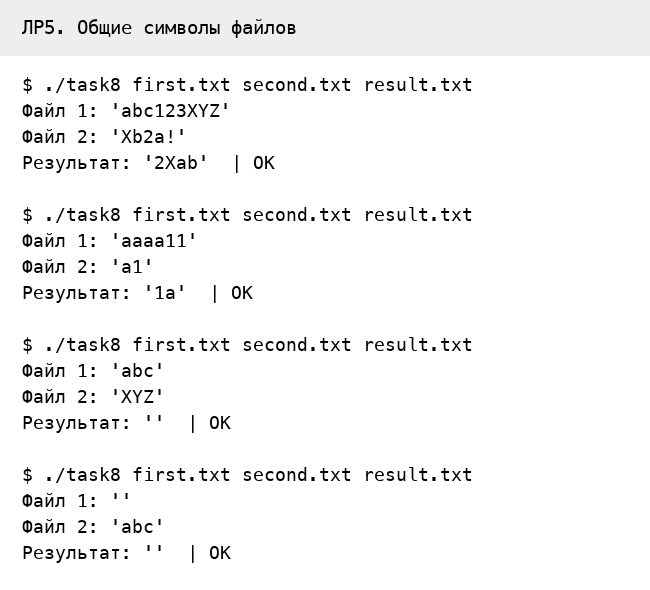

In [6]:
from pathlib import Path
import subprocess, tempfile
p = Path('Lab_5/task8').resolve()
with tempfile.TemporaryDirectory() as directory:
    d = Path(directory)
    for i,(first,second) in enumerate([(b'abc123XYZ',b'Xb2a!'),(b'aaaa11',b'a1'),(b'abc',b'XYZ'),(b'',b'abc')],1):
        (d/'first.txt').write_bytes(first)
        (d/'second.txt').write_bytes(second)
        target = d/f'result{i}.txt'
        subprocess.run([str(p),str(d/'first.txt'),str(d/'second.txt'),str(target)],check=True)
        result = target.read_bytes()
        assert result == bytes(sorted(set(first)&set(second)))
        print('$ ./task8 first.txt second.txt result.txt')
        print('Файл 1:',repr(first.decode()))
        print('Файл 2:',repr(second.decode()))
        print('Результат:',repr(result.decode()),' | OK\n')

## Задача 9. Только числа из текстового файла → второй файл
Число — непрерывная последовательность цифр 0–9. Каждое число записывается на отдельной строке. Выходной файл создаётся новым.

In [7]:
%%writefile Lab_5/task9.asm
; Число — непрерывная последовательность цифр 0..9; по одному на строку.
; ./task9 input.txt new_numbers.txt
format ELF64
public _start
section '.text' executable
_start:
    cmp qword [rsp], 3
    jne error
    mov rdi, [rsp+16]
    call open_read
    mov r12, rax
    mov rdi, [rsp+24]
    call open_output
    mov r13, rax
    xor ebx, ebx                    ; внутри числа = 1
.loop:
    mov rdi, r12
    call read_byte
    test rax, rax
    jz .done
    cmp byte [symbol], '0'
    jb .separator
    cmp byte [symbol], '9'
    ja .separator
    mov rdi, r13
    call write_byte
    mov ebx, 1
    jmp .loop
.separator:
    test ebx, ebx
    jz .loop
    mov byte [symbol], 10
    mov rdi, r13
    call write_byte
    xor ebx, ebx
    jmp .loop
.done:
    test ebx, ebx
    jz .close
    mov byte [symbol], 10
    mov rdi, r13
    call write_byte
.close:
    mov rdi, r12
    call close_file
    mov rdi, r13
    call close_file
    jmp exit
include 'file_io.inc'

Writing Lab_5/task9.asm


In [8]:
%%bash
set -e
cd Lab_5
fasm task9.asm task9.o >/dev/null
ld task9.o -o task9

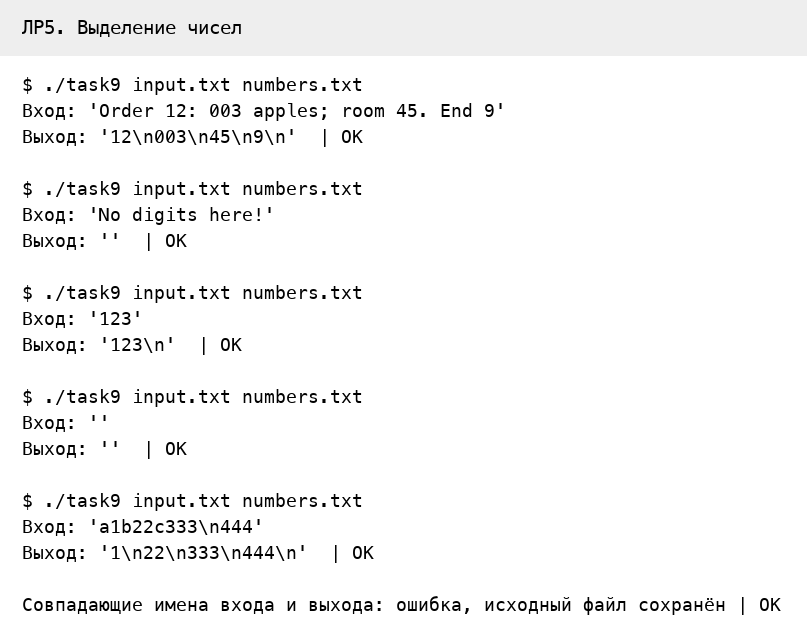

In [9]:
from pathlib import Path
import subprocess, tempfile, re
p = Path('Lab_5/task9').resolve()
with tempfile.TemporaryDirectory() as directory:
    d = Path(directory)
    for i,text in enumerate([b'Order 12: 003 apples; room 45. End 9',b'No digits here!',b'123',b'',b'a1b22c333\n444'],1):
        (d/'input.txt').write_bytes(text)
        target = d/f'numbers{i}.txt'
        subprocess.run([str(p),str(d/'input.txt'),str(target)],check=True)
        result = target.read_bytes()
        assert result == b''.join(x+b'\n' for x in re.findall(rb'[0-9]+',text))
        print('$ ./task9 input.txt numbers.txt')
        print('Вход:',repr(text.decode()))
        print('Выход:',repr(result.decode()),' | OK\n')
    # Попытка записи в существующий входной файл должна завершиться ошибкой.
    before = (d/'input.txt').read_bytes()
    r = subprocess.run([str(p),str(d/'input.txt'),str(d/'input.txt')],capture_output=True,text=True)
    assert r.returncode != 0 and (d/'input.txt').read_bytes() == before
    print('Совпадающие имена входа и выхода: ошибка, исходный файл сохранён | OK')